# 04 — Figures (layout preview)

Figure scaffolding for the Dual-Duty Tax analysis, with an explicit **`USE_FAKE`** switch. Sid's `route_features.parquet` handoff **has arrived** (real data), so the default is real mode; the synthetic fixture is kept only as a layout-preview stand-in.

- **Real mode** (`USE_FAKE=False`, default) reads `data/route_features.parquet` and writes to `figures/`. It **fails clearly** if the handoff is missing and **never falls back** to synthetic data.
- **Fake mode** (`USE_FAKE=True`) reads `data/route_features_FAKE.parquet` and writes previews only to `figures/mock/` with a SYNTHETIC watermark.

In [1]:
import sys
from pathlib import Path

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / 'src' / 'config.py').exists():
        sys.path.insert(0, str(_p / 'src'))
        _ROOT = _p
        break
else:
    raise SystemExit('Could not locate src/config.py from cwd.')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import (
    DATA_DIR, ROOT, TE_RB_POSITIONS, RB_POSITIONS,
    END_EVENTS, PASS_FORWARD_FALLBACK, NO_THROW_EVENTS,
)
print('project root:', ROOT)


project root: C:\Users\isaac\CodingProjects\NYUDataBowl


## Mode switch

In [2]:
# === MODE SWITCH ============================================================
USE_FAKE = False  # False -> real handoff data/route_features.parquet, figures/
                  # True  -> synthetic fixture, figures/mock/ only (layout testing)
# ============================================================================

REQUIRED_COLS = ['gameId','playId','nflId','group','officialPosition','displayName',
                 't_throw','t_release','depth_at_throw','sep_at_throw','end_event',
                 'los_check_diff_yd','depth_at_snap','depth_gain_at_throw',
                 't_release_rel','released_rel','t_release_rel_capped']
print('USE_FAKE =', USE_FAKE)

USE_FAKE = False


## Input checks (no silent fallback)

In [3]:
if USE_FAKE:
    DATA_PATH = DATA_DIR / 'route_features_FAKE.parquet'
    FIG_DIR = ROOT / 'figures' / 'mock'
    WATERMARK = 'SYNTHETIC DEMO - NOT RESULTS'
else:
    DATA_PATH = DATA_DIR / 'route_features.parquet'
    FIG_DIR = ROOT / 'figures'
    WATERMARK = None

if not DATA_PATH.exists():
    if USE_FAKE:
        raise FileNotFoundError(
            f'Synthetic fixture missing: {DATA_PATH}. '
            f'Run notebooks/make_fake_fixture.py to generate it.')
    else:
        raise FileNotFoundError(
            f'Real handoff missing: {DATA_PATH}. '
            f'Sid has not delivered data/route_features.parquet yet. '
            f'Set USE_FAKE=True to develop against the synthetic fixture instead. '
            f'There is no automatic fallback to synthetic data in real mode.')
print('data path:', DATA_PATH)
print('figure dir:', FIG_DIR)


data path: C:\Users\isaac\CodingProjects\NYUDataBowl\data\route_features.parquet
figure dir: C:\Users\isaac\CodingProjects\NYUDataBowl\figures


## Load & validate schema

In [4]:
df = pd.read_parquet(DATA_PATH)

# schema + dtype checks
assert list(df.columns) == REQUIRED_COLS, f'columns mismatch: {list(df.columns)}'
for c in ['gameId','playId','nflId']:
    assert pd.api.types.is_integer_dtype(df[c]), f'{c} not integer'
for c in ['t_throw','t_release','depth_at_throw','sep_at_throw',
          'los_check_diff_yd','depth_at_snap','depth_gain_at_throw',
          't_release_rel','t_release_rel_capped']:
    assert pd.api.types.is_float_dtype(df[c]), f'{c} not float'
assert pd.api.types.is_bool_dtype(df['released_rel']), 'released_rel not bool'
assert set(df['group'].dropna().unique()).issubset({'chip','leak','clean'})
assert set(df['officialPosition'].dropna().unique()).issubset(set(TE_RB_POSITIONS))
assert set(df['end_event'].dropna().unique()).issubset(set(END_EVENTS) | {PASS_FORWARD_FALLBACK})

# key uniqueness
assert df.duplicated(['gameId','playId','nflId']).sum() == 0, 'duplicate keys'

# timing / value constraints
assert (df['t_throw'] >= 0).all(), 'negative t_throw'
assert (df['sep_at_throw'] >= 0).all(), 'negative sep_at_throw'
_obs = df['t_release'].notna()
assert (df.loc[_obs,'t_release'] >= 0).all(), 'negative observed t_release'
assert (df.loc[_obs,'t_release'] <= df.loc[_obs,'t_throw']).all(), 't_release > t_throw'

print('rows:', len(df))
print('validation OK')
print('group counts:'); print(df['group'].value_counts().to_string())
print('end_event counts:'); print(df['end_event'].value_counts().to_string())
print('missing t_release:', int(df['t_release'].isna().sum()))


rows: 16272
validation OK
group counts:
group
clean    14549
chip      1361
leak       362
end_event counts:
end_event
pass_forward             14362
run                        927
qb_sack                    808
qb_strip_sack              102
autoevent_passforward       73
missing t_release: 6323


## Layout preview (NOT findings)

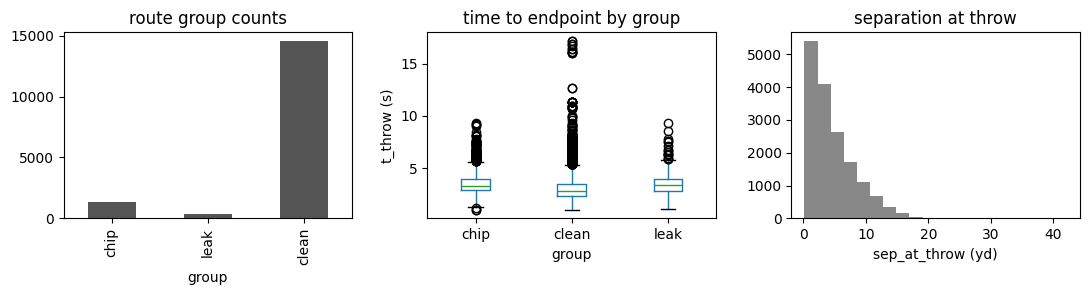

saved: C:\Users\isaac\CodingProjects\NYUDataBowl\figures\preview_groups.png


In [5]:
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(11,3.2))

# panel 1: group counts
df['group'].value_counts().reindex(['chip','leak','clean']).plot.bar(ax=axes[0], color='#555')
axes[0].set_title('route group counts')
axes[0].set_xlabel('group')

# panel 2: time to endpoint by group
df.boxplot(column='t_throw', by='group', ax=axes[1], grid=False)
axes[1].set_title('time to endpoint by group')
axes[1].set_xlabel('group'); axes[1].set_ylabel('t_throw (s)')
plt.suptitle('')

# panel 3: separation distribution
axes[2].hist(df['sep_at_throw'], bins=20, color='#888')
axes[2].set_title('separation at throw')
axes[2].set_xlabel('sep_at_throw (yd)')

if WATERMARK:
    fig.text(0.5, 0.5, WATERMARK, ha='center', va='center',
             fontsize=22, color='red', alpha=0.18, rotation=30)
    fig.suptitle('SYNTHETIC DEMO - NOT RESULTS', color='red')

plt.tight_layout()
out = FIG_DIR / ('preview_groups' + ('_FAKE' if USE_FAKE else '') + '.png')
plt.savefig(out, dpi=120)
plt.show()
print('saved:', out)


## Interpretation

Do not read the panels above as findings. They are a **layout preview** to confirm the figure plumbing works on the schema. The real handoff is now in place (`USE_FAKE=False` by default); these panels are still a layout preview, not final findings. Flip `USE_FAKE=True` for a synthetic layout preview.

> Synthetic previews live only in `figures/mock/`. Real mode writes to `figures/` and fails loudly if the handoff is missing.

---
# Stay or Go receiving side: separation when backs release

This section joins **Sid's real `data/route_features.parquet` handoff** to the Stay-or-Go play context from notebook 03 (`data/isaac/stayorgo_play_context.csv`) and summarizes the separation of **releasing** RB/FB on `go_only` plays. It reads inputs directly from the local workspace and **never** uses `route_features_FAKE.parquet`.

**Ownership:** this is Isaac's notebook. Sid's config, feature pipeline, notebooks and handoff files are not modified. The prompt's expected column `position` is named **`officialPosition`** in Sid's actual handoff; we adapt to the real name locally here (confirmed against `outputs/handoff_to_isaac.txt`).

**Endpoint caveat (from Sid's handoff note).** `end_event` takes values `{pass_forward, autoevent_passforward, run, qb_sack, qb_strip_sack}`. `sep_at_throw` is measured at the play-window end, which pools **actual throws** with **no-throw endpoints** (sacks, runs). We therefore label the metric **"separation at play-window end"**, not "separation at throw," and report endpoint counts. A `pass_forward`-only sensitivity is included.

**Endpoint timing is shared across a play's route records.** Sid's pipeline (`src/route_features.py`) computes a **single** `end_frame`/`end_event` per **play** (the first `END_EVENTS` frame after the snap, with `autoevent_passforward` as the documented last-resort fallback) and writes that same endpoint onto **every** route record of the play. So `t_throw` and `end_event` are identical across all routes on a play — they describe the *play's* endpoint, not an independent per-route throw. We **preserve Sid's endpoint definition unchanged** and do not reclassify any record.

**Interpretation guard.** This is **observed separation when backs release**. It does **not** estimate the separation a *blocking* back would have achieved, and it does **not** establish that releasing is the better decision. TE and RB are never pooled (we restrict to RB/FB here).

## Switch to real mode and validate the handoff

In [6]:
# Real-mode integration. Requires the validated real handoff; never the FAKE file.
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / 'src' / 'config.py').exists():
        sys.path.insert(0, str(_p / 'src')); break
from config import DATA_DIR, ROOT, RB_POSITIONS, N_BOOTSTRAP, RANDOM_SEED

RF_PATH = DATA_DIR / 'route_features.parquet'
CTX_PATH = DATA_DIR / 'isaac' / 'stayorgo_play_context.csv'
assert RF_PATH.name != 'route_features_FAKE.parquet'
if not RF_PATH.exists():
    raise FileNotFoundError(f'Real handoff missing: {RF_PATH}. No synthetic fallback in real mode.')
assert CTX_PATH.exists(), f'Stay-or-Go context missing: {CTX_PATH} (run notebook 03 first)'

rf = pd.read_parquet(RF_PATH)
NO_THROW = {'qb_sack', 'qb_strip_sack', 'run'}        # per handoff: no actual throw
THROW_LIKE = {'pass_forward', 'autoevent_passforward'}

# validate schema against the documented real handoff (adapt to officialPosition)
expected = ['gameId','playId','nflId','group','officialPosition','displayName','t_throw',
            't_release','depth_at_throw','sep_at_throw','end_event','los_check_diff_yd',
            'depth_at_snap','depth_gain_at_throw','t_release_rel','released_rel','t_release_rel_capped']
print('columns match documented handoff:', list(rf.columns) == expected)
for c in ['gameId','playId','nflId']:
    assert pd.api.types.is_integer_dtype(rf[c]), f'{c} not integer'
assert rf.duplicated(['gameId','playId','nflId']).sum() == 0, 'route features keys not unique'
assert (rf['sep_at_throw'].dropna() >= 0).all(), 'negative separation'
print('rows:', len(rf), '| unique nflId:', rf['nflId'].nunique(),
      '| unique (game,play):', rf.drop_duplicates(['gameId','playId']).shape[0])
print('group counts:', rf['group'].value_counts().to_dict())
print('group x position:'); print(rf.groupby(['group','officialPosition']).size().to_string())
print('sep_at_throw NaN:', int(rf['sep_at_throw'].isna().sum()))
print('end_event counts:'); print(rf['end_event'].value_counts(dropna=False).to_string())
print('\nfive sample rows:')
print(rf[['gameId','playId','nflId','group','officialPosition','t_throw',
          'sep_at_throw','end_event']].head(5).to_string())

columns match documented handoff: True
rows: 16272 | unique nflId: 257 | unique (game,play): 8216
group counts: {'clean': 14549, 'chip': 1361, 'leak': 362}
group x position:
group  officialPosition
chip   FB                    55
       RB                   539
       TE                   767
clean  FB                   304
       RB                  6378
       TE                  7867
leak   FB                    15
       RB                    18
       TE                   329
sep_at_throw NaN: 0
end_event counts:
end_event
pass_forward             14362
run                        927
qb_sack                    808
qb_strip_sack              102
autoevent_passforward       73

five sample rows:
       gameId  playId  nflId  group officialPosition  t_throw  sep_at_throw     end_event
0  2021090900      97  35481  clean               TE      3.4      1.914001  pass_forward
1  2021090900      97  39985  clean               RB      3.4      9.825808  pass_forward
2  2021090900     137 

## Match eligible releasing backs to features; join context many-to-one

Eligible route participants = **RB/FB** (`RB_POSITIONS`) with `pff_role == 'Pass Route'` on **traditional** dropbacks — the same releasing-back population that feeds the Stay-or-Go `go_only` category in notebook 03. We match these to route features on **all three keys** `(gameId, playId, nflId)`, then join the one-row-per-play Stay-or-Go context **many-to-one** on `(gameId, playId)`. Coverage is **measured eligible / all eligible**; missing separation stays missing (never set to zero). Missing and extra keys are audited.

In [7]:
pff = pd.read_csv(DATA_DIR / 'pffScoutingData.csv')
players = pd.read_csv(DATA_DIR / 'players.csv')
plays = pd.read_csv(DATA_DIR / 'plays.csv')
ctx = pd.read_csv(CTX_PATH)

pff = pff.merge(players[['nflId','officialPosition']], on='nflId', how='left')
pff = pff.merge(plays[['gameId','playId','dropBackType']], on=['gameId','playId'], how='left')
trad = pff[pff['dropBackType'] == 'TRADITIONAL']

# eligible releasing backs (one row per participant)
elig = (trad[(trad['officialPosition'].isin(RB_POSITIONS)) & (trad['pff_role'] == 'Pass Route')]
        [['gameId','playId','nflId','officialPosition']].drop_duplicates())
assert elig.duplicated(['gameId','playId','nflId']).sum() == 0
print('eligible RB/FB Pass Route participants (traditional):', len(elig))

# match to features by ALL THREE keys
rf_k = rf[['gameId','playId','nflId','officialPosition','sep_at_throw','end_event','group']]
matched = elig.merge(rf_k, on=['gameId','playId','nflId'], how='left', suffixes=('','_rf'))
n_elig = len(matched)
n_meas = int(matched['sep_at_throw'].notna().sum())
sep_coverage = n_meas / n_elig
print(f'eligible={n_elig} measured={n_meas} missing={n_elig - n_meas} '
      f'| separation coverage = {sep_coverage:.4f}')

# audits: position agreement, missing keys, extra keys
pos_mismatch = int((matched['officialPosition_rf'].notna() &
                    (matched['officialPosition'] != matched['officialPosition_rf'])).sum())
missing_keys = matched[matched['sep_at_throw'].isna()][['gameId','playId','nflId']]
rf_rb = rf[rf['officialPosition'].isin(RB_POSITIONS)]
extra = rf_rb.merge(elig[['gameId','playId','nflId']].assign(_e=1),
                    on=['gameId','playId','nflId'], how='left')
n_extra = int(extra['_e'].isna().sum())
print('position mismatches on matched rows:', pos_mismatch)
print('missing keys (eligible but no measured sep):', len(missing_keys))
print('extra keys (route-feature RB/FB not in eligible set):', n_extra,
      '-> RB/FB on non-traditional or non-route rows; expected, audited not merged')

# many-to-one context join
assert ctx.duplicated(['gameId','playId']).sum() == 0, 'context not one-row-per-play'
recv = matched.merge(ctx[['gameId','playId','n_rushers','rb_category']],
                     on=['gameId','playId'], how='left')
assert len(recv) == n_elig, 'context join multiplied rows'
print('rows after many-to-one context join:', len(recv),
      '| rows with no context match:', int(recv['rb_category'].isna().sum()))

eligible RB/FB Pass Route participants (traditional): 5675
eligible=5675 measured=5620 missing=55 | separation coverage = 0.9903
position mismatches on matched rows: 0
missing keys (eligible but no measured sep): 55
extra keys (route-feature RB/FB not in eligible set): 1689 -> RB/FB on non-traditional or non-route rows; expected, audited not merged
rows after many-to-one context join: 5675 | rows with no context match: 0


## Receiving summary for go_only plays, by rusher slice

For `go_only` plays we take the **median measured RB/FB separation within each play**, then the **median across plays**. Reported per slice: eligible plays/routes, measured plays/routes, missing counts, coverage, a **95% percentile CI** from **1000 whole-game bootstrap resamples** (fixed seed, sampled-game multiplicity preserved), and **unusable draws**. `5+ rushers` and `exactly 4 rushers` are reported **separately** (the 4-rusher slice is a baseline, not pooled). Endpoint counts accompany each slice; separation is at the **play-window end**, not necessarily a throw.

In [8]:
# receiving_summary takes the FULL eligible frame for the slice. We count three
# disjoint fates for each eligible route:
#   measured_in_scope  -- sep observed AND (no endpoint restriction, or endpoint in it)
#   known_no_throw     -- sep observed but endpoint is a documented no-throw (sack/run)
#   parquet_absent     -- route missing from the handoff entirely (endpoint UNKNOWN)
# known_no_throw are NOT missing measurements -- the route simply did not reach a throw.
# parquet_absent are genuinely unknown. We never collapse these two together, and we
# never pre-filter parquet_absent rows out of the denominator.
def receiving_summary(df_elig, seed, label, endpoint_restrict=None):
    sep_obs = df_elig['sep_at_throw'].notna()
    in_scope = sep_obs & (df_elig['end_event'].isin(endpoint_restrict)
                          if endpoint_restrict is not None else True)
    meas = df_elig[in_scope]
    n_elig_routes = len(df_elig)                       # full eligible denominator
    n_meas_routes = len(meas)
    n_elig_plays = df_elig[['gameId','playId']].drop_duplicates().shape[0]
    n_meas_plays = meas[['gameId','playId']].drop_duplicates().shape[0]
    play_med = meas.groupby(['gameId','playId'])['sep_at_throw'].median()  # within-play median
    point = float(play_med.median()) if len(play_med) else np.nan          # median across plays
    # whole-game bootstrap on play-level medians; preserve sampled-game multiplicity
    pm = play_med.reset_index()
    games = pm['gameId'].unique(); n_games = len(games)
    by_game = {g: pm.loc[pm['gameId'] == g, 'sep_at_throw'].to_numpy() for g in games}
    rng = np.random.default_rng(seed)
    draws = []; unusable = 0
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, n_games, size=n_games)
        vals = np.concatenate([by_game[games[i]] for i in idx]) if n_games else np.array([])
        if vals.size == 0:
            unusable += 1; continue
        draws.append(np.median(vals))
    ci = ((float(np.percentile(draws, 2.5)), float(np.percentile(draws, 97.5)))
          if draws else (np.nan, np.nan))
    ep = df_elig['end_event'].value_counts(dropna=False).to_dict()
    n_throwlike = int(df_elig['end_event'].isin(THROW_LIKE).sum())
    n_known_nothrow = int(df_elig['end_event'].isin(list(NO_THROW)).sum())
    n_parquet_absent = int(df_elig['sep_at_throw'].isna().sum())  # endpoint unknown
    # share of ALL eligible routes that have a measured in-scope separation.
    # NOTE: this is a share-of-eligible, NOT 'coverage among throw routes'. True
    # throw-route coverage would need an independent endpoint table that also
    # classifies parquet_absent routes; we do not have one (see prose).
    share_eligible_in_scope = n_meas_routes / n_elig_routes
    # conservative lower bound on throw-route coverage, assuming EVERY parquet_absent
    # route was actually a throw (so it belongs in the throw denominator but is unmeasured).
    # Only meaningful for the throw-restricted slices.
    if endpoint_restrict is not None:
        denom_lb = n_meas_routes + n_parquet_absent
        conservative_lb = n_meas_routes / denom_lb if denom_lb else np.nan
    else:
        conservative_lb = np.nan
    print(f'[{label}] elig_plays={n_elig_plays} meas_plays={n_meas_plays} '
          f'elig_routes={n_elig_routes} measured_in_scope={n_meas_routes}')
    print(f'    known_no_throw={n_known_nothrow} (not missing) | '
          f'parquet_absent={n_parquet_absent} (endpoint unknown)')
    print(f'    share_of_eligible_with_measured_in_scope_sep = {share_eligible_in_scope:.4f}')
    if endpoint_restrict is not None:
        print(f'    conservative throw-route coverage lower bound '
              f'(assume all parquet_absent were throws) = {conservative_lb:.4f}')
        print('    true throw-route coverage: UNAVAILABLE (no independent endpoint table)')
    print(f'    median-of-play-median separation = {point:.4f} yd '
          f'CI=[{ci[0]:.4f},{ci[1]:.4f}] (valid={len(draws)} unusable={unusable})')
    print(f'    endpoints: {ep} | throw-like={n_throwlike} no-throw={n_known_nothrow}')
    return dict(label=label, n_elig_plays=n_elig_plays, n_meas_plays=n_meas_plays,
                n_elig_routes=n_elig_routes, n_meas_routes=n_meas_routes,
                share_eligible_in_scope=share_eligible_in_scope,
                conservative_lb=conservative_lb, restricted=(endpoint_restrict is not None),
                point=point, ci_low=ci[0], ci_high=ci[1], n_valid=len(draws),
                unusable=unusable, n_throwlike=n_throwlike,
                n_known_nothrow=n_known_nothrow, n_parquet_absent=n_parquet_absent,
                endpoints=ep)
go = recv[recv['rb_category'] == 'go_only']
R5 = receiving_summary(go[go['n_rushers'] >= 5], RANDOM_SEED + 20, 'go_only_5plus_rushers')
R4 = receiving_summary(go[go['n_rushers'] == 4], RANDOM_SEED + 21, 'go_only_4_rushers_baseline')

[go_only_5plus_rushers] elig_plays=892 meas_plays=876 elig_routes=949 measured_in_scope=931
    known_no_throw=65 (not missing) | parquet_absent=18 (endpoint unknown)
    share_of_eligible_with_measured_in_scope_sep = 0.9810
    median-of-play-median separation = 5.5853 yd CI=[5.2333,6.0199] (valid=1000 unusable=0)
    endpoints: {'pass_forward': 859, 'qb_sack': 55, nan: 18, 'qb_strip_sack': 10, 'autoevent_passforward': 7} | throw-like=866 no-throw=65


[go_only_4_rushers_baseline] elig_plays=4044 meas_plays=4014 elig_routes=4267 measured_in_scope=4233
    known_no_throw=243 (not missing) | parquet_absent=34 (endpoint unknown)
    share_of_eligible_with_measured_in_scope_sep = 0.9920
    median-of-play-median separation = 6.2385 yd CI=[5.9621,6.5053] (valid=1000 unusable=0)
    endpoints: {'pass_forward': 3977, 'qb_sack': 207, nan: 34, 'qb_strip_sack': 31, 'autoevent_passforward': 13, 'run': 5} | throw-like=3990 no-throw=243


### Throw-like-only sensitivity (with honest coverage accounting)

Restricting the **measured** set to throw-like endpoints — `pass_forward` **and** `autoevent_passforward` (the `THROW_LIKE` set, matching the audit) — to show how much the pooled play-window-end figure depends on including no-throw endpoints.

**What the ratio means.** `866/949` (5+) and `3990/4267` (4-rusher) are the **share of all eligible routes with a measured throw-end separation** — *not* "coverage among throw routes." The denominator is every eligible releasing back, and the numerator only the ones with a measured throw-like endpoint.

**Two different exclusions, reported separately:**
- **Known no-throw routes** (ended in sack/run): 65 (5+) and 243 (4-rusher). These are **not missing measurements** — the route simply never reached a throw, so it is correctly outside a throw-only numerator.
- **Parquet-absent routes** (eligible but missing from the handoff, endpoint **unknown**): 18 (5+) and 34 (4-rusher).

**True throw-route coverage is UNAVAILABLE.** Computing it would require an independent play-level endpoint table that classifies the endpoint of routes **absent from the parquet** too. No such table exists in the workspace (`plays.csv.passResult` is a play-level pass outcome, not a per-route endpoint, and disagrees with the tracking `end_event` at the margin), and we do not modify Sid's pipeline to produce one. So throw-route coverage is reported as **unavailable**.

**On the `end_event` vs `passResult` discrepancy.** Across the full handoff there are **22 throw-like route records on 10 sack-labeled plays** (tracking `end_event ∈ {pass_forward, autoevent_passforward}` while `plays.csv.passResult == 'S'`); the verification cell below recomputes these counts from the real inputs. Because the endpoint is **shared across every route record on a play** (above), these 22 records are **not** evidence that individual routes had different throw endpoints — they reflect a **discrepancy between the tracking endpoint events and `plays.csv.passResult` on those 10 plays**, not per-route throw timing. We keep **Sid's documented tracking endpoint definition** as the endpoint of record and do **not** silently reclassify any record or alter his pipeline.

**Conservative lower bound.** If we **assume every parquet-absent route was a throw** (the least favorable case for coverage), throw-route coverage is at least `866/(866+18) = 0.980` (5+) and `3990/(3990+34) = 0.992` (4-rusher). This is an explicit worst-case assumption, not a measurement.

This uses the documented event normalization from Sid's handoff note; it is a sensitivity check, not the headline number.

In [9]:
# Verify the end_event vs plays.csv.passResult discrepancy from the REAL inputs.
# Endpoint timing/event is shared across all route records on a play (Sid's
# pipeline), so a throw-like end_event on a sack-labeled play is a play-level
# tracking-vs-passResult discrepancy, NOT a per-route throw endpoint. We only
# REPORT this; we never reclassify records or touch Sid's pipeline.
_plays_pr = pd.read_csv(DATA_DIR / 'plays.csv')[['gameId','playId','passResult']]
assert _plays_pr.duplicated(['gameId','playId']).sum() == 0, 'passResult not one-per-play'
_rf_pr = rf.merge(_plays_pr, on=['gameId','playId'], how='left')
_tl_on_sack = _rf_pr[_rf_pr['end_event'].isin(THROW_LIKE) & (_rf_pr['passResult'] == 'S')]
_n_records = len(_tl_on_sack)
_n_plays = _tl_on_sack[['gameId','playId']].drop_duplicates().shape[0]
print(f'throw-like route records on sack-labeled (passResult==S) plays: {_n_records} records '
      f'across {_n_plays} unique plays')
# endpoint is shared within a play -> records-per-play are all the same endpoint
_per_play_ends = _tl_on_sack.groupby(['gameId','playId'])['end_event'].nunique()
print('each affected play has a single shared end_event across its routes:',
      bool((_per_play_ends == 1).all()))
print('interpretation: tracking endpoint vs plays.csv.passResult discrepancy on '
      f'{_n_plays} plays; NOT per-route throw endpoints. Sid endpoint definition preserved.')

throw-like route records on sack-labeled (passResult==S) plays: 22 records across 10 unique plays
each affected play has a single shared end_event across its routes: True
interpretation: tracking endpoint vs plays.csv.passResult discrepancy on 10 plays; NOT per-route throw endpoints. Sid endpoint definition preserved.


In [10]:
# Throw-like-only sensitivity: restrict the MEASURED numerator to throw-like endpoints
# (pass_forward AND autoevent_passforward), keeping the FULL eligible denominator.
# receiving_summary reports known_no_throw and parquet_absent SEPARATELY and a
# conservative throw-route coverage lower bound (assume all parquet_absent were throws).
# True throw-route coverage is unavailable (no independent endpoint table).
S5 = receiving_summary(go[go['n_rushers'] >= 5], RANDOM_SEED + 30,
                       'go_only_5plus_rushers_throwlike_only', endpoint_restrict=THROW_LIKE)
S4 = receiving_summary(go[go['n_rushers'] == 4], RANDOM_SEED + 31,
                       'go_only_4_rushers_baseline_throwlike_only', endpoint_restrict=THROW_LIKE)

[go_only_5plus_rushers_throwlike_only] elig_plays=892 meas_plays=813 elig_routes=949 measured_in_scope=866
    known_no_throw=65 (not missing) | parquet_absent=18 (endpoint unknown)
    share_of_eligible_with_measured_in_scope_sep = 0.9125
    conservative throw-route coverage lower bound (assume all parquet_absent were throws) = 0.9796
    true throw-route coverage: UNAVAILABLE (no independent endpoint table)
    median-of-play-median separation = 5.6283 yd CI=[5.3263,6.0701] (valid=1000 unusable=0)
    endpoints: {'pass_forward': 859, 'qb_sack': 55, nan: 18, 'qb_strip_sack': 10, 'autoevent_passforward': 7} | throw-like=866 no-throw=65


[go_only_4_rushers_baseline_throwlike_only] elig_plays=4044 meas_plays=3784 elig_routes=4267 measured_in_scope=3990
    known_no_throw=243 (not missing) | parquet_absent=34 (endpoint unknown)
    share_of_eligible_with_measured_in_scope_sep = 0.9351
    conservative throw-route coverage lower bound (assume all parquet_absent were throws) = 0.9916
    true throw-route coverage: UNAVAILABLE (no independent endpoint table)
    median-of-play-median separation = 6.3458 yd CI=[6.0949,6.6129] (valid=1000 unusable=0)
    endpoints: {'pass_forward': 3977, 'qb_sack': 207, nan: 34, 'qb_strip_sack': 31, 'autoevent_passforward': 13, 'run': 5} | throw-like=3990 no-throw=243


## Save receiving summaries + coverage audit to `data/isaac/`

In [11]:
OUT = ROOT / 'data' / 'isaac'
OUT.mkdir(parents=True, exist_ok=True)

def summary_row(R, endpoint_scope):
    # ratio_label distinguishes the honest meaning of the share for each scope
    if R['restricted']:
        ratio_label = 'share_of_eligible_with_measured_throwend_sep'
        true_cov = 'unavailable_no_independent_endpoint_table'
    else:
        ratio_label = 'share_of_eligible_with_measured_playwindowend_sep'
        true_cov = 'not_applicable_endpoint_not_restricted'
    return dict(
        population=R['label'], metric='median_of_play_median_separation',
        estimate=round(R['point'], 6), ci_low=round(R['ci_low'], 6), ci_high=round(R['ci_high'], 6),
        unit='yards', endpoint_scope=endpoint_scope,
        eligible_plays=R['n_elig_plays'], measured_plays=R['n_meas_plays'],
        eligible_routes=R['n_elig_routes'], measured_routes=R['n_meas_routes'],
        ratio_label=ratio_label,
        share_of_eligible=round(R['share_eligible_in_scope'], 6),
        known_no_throw_routes=R['n_known_nothrow'],
        parquet_absent_routes=R['n_parquet_absent'],
        true_throw_route_coverage=true_cov,
        conservative_throw_coverage_lb=(round(R['conservative_lb'], 6)
                                        if R['restricted'] else np.nan),
        conservative_lb_assumption=('all_parquet_absent_routes_assumed_throws'
                                    if R['restricted'] else ''),
        n_valid_draws=R['n_valid'], n_unusable_draws=R['unusable'],
        throw_like_endpoints=R['n_throwlike'], no_throw_endpoints=R['n_known_nothrow'],
        notes=('observed separation at play-window end when backs release; not a blocking '
               'counterfactual. share_of_eligible is NOT throw-route coverage.'))

recv_summary = pd.DataFrame([
    summary_row(R5, 'play_window_end_all'),
    summary_row(R4, 'play_window_end_all'),
    summary_row(S5, 'throwlike_only'),
    summary_row(S4, 'throwlike_only'),
])
recv_summary.to_csv(OUT / 'stayorgo_receiving_summary.csv', index=False)

# coverage / key audit (overall + per slice fate breakdown + endpoint breakdown)
audit_rows = [
    dict(item='route_features_source', value='data/route_features.parquet (REAL handoff)'),
    dict(item='eligible_rbfb_route_participants', value=n_elig),
    dict(item='measured_separation_any_endpoint', value=n_meas),
    dict(item='parquet_absent_separation', value=n_elig - n_meas),
    dict(item='share_eligible_with_any_measured_sep', value=round(sep_coverage, 6)),
    dict(item='true_throw_route_coverage', value='unavailable_no_independent_endpoint_table'),
    dict(item='endpoint_vs_passResult_throwlike_on_sack_records', value=int(_n_records)),
    dict(item='endpoint_vs_passResult_throwlike_on_sack_plays', value=int(_n_plays)),
    dict(item='endpoint_vs_passResult_note',
         value='play-level tracking-endpoint vs plays.csv.passResult discrepancy; endpoint shared across a play routes; not per-route throw endpoints; Sid pipeline unchanged'),
    dict(item='position_mismatches_matched', value=pos_mismatch),
    dict(item='extra_rfkeys_rbfb_not_eligible', value=n_extra),
    dict(item='context_join_no_match', value=int(recv['rb_category'].isna().sum())),
    dict(item='n_bootstrap', value=N_BOOTSTRAP),
    dict(item='random_seed', value=RANDOM_SEED),
]
# per-slice fate breakdown (measured / known_no_throw / parquet_absent) + conservative LB
for R in (R5, R4, S5, S4):
    audit_rows.append(dict(item=f"{R['label']}__measured_in_scope", value=R['n_meas_routes']))
    audit_rows.append(dict(item=f"{R['label']}__known_no_throw", value=R['n_known_nothrow']))
    audit_rows.append(dict(item=f"{R['label']}__parquet_absent", value=R['n_parquet_absent']))
    audit_rows.append(dict(item=f"{R['label']}__share_of_eligible",
                           value=round(R['share_eligible_in_scope'], 6)))
    if R['restricted']:
        audit_rows.append(dict(item=f"{R['label']}__conservative_throw_coverage_lb",
                               value=round(R['conservative_lb'], 6)))
for R in (R5, R4):
    for ev, ct in R['endpoints'].items():
        audit_rows.append(dict(item=f"endpoint__{R['label']}__{ev}", value=int(ct)))
recv_audit = pd.DataFrame(audit_rows)
recv_audit.to_csv(OUT / 'stayorgo_receiving_audit.csv', index=False)

print('saved receiving tables to', OUT)
print('  stayorgo_receiving_summary.csv rows:', len(recv_summary))
print('  stayorgo_receiving_audit.csv rows:', len(recv_audit))
recv_summary

saved receiving tables to C:\Users\isaac\CodingProjects\NYUDataBowl\data\isaac
  stayorgo_receiving_summary.csv rows: 4
  stayorgo_receiving_audit.csv rows: 43


,population,metric,estimate,ci_low,ci_high,unit,endpoint_scope,eligible_plays,measured_plays,eligible_routes,...,known_no_throw_routes,parquet_absent_routes,true_throw_route_coverage,conservative_throw_coverage_lb,conservative_lb_assumption,n_valid_draws,n_unusable_draws,throw_like_endpoints,no_throw_endpoints,notes
0,go_only_5plus_rushers,median_of_play_median_separation,5.585259,5.233323,6.019943,yards,play_window_end_all,892,876,949,...,65,18,not_applicable_endpoint_not_restricted,NaN,,1000,0,866,65,observed separation at play-window end when ba...
1,go_only_4_rushers_baseline,median_of_play_median_separation,6.238549,5.962086,6.505329,yards,play_window_end_all,4044,4014,4267,...,243,34,not_applicable_endpoint_not_restricted,NaN,,1000,0,3990,243,observed separation at play-window end when ba...
2,go_only_5plus_rushers_throwlike_only,median_of_play_median_separation,5.628259,5.326343,6.070095,yards,throwlike_only,892,813,949,...,65,18,unavailable_no_independent_endpoint_table,0.979638,all_parquet_absent_routes_assumed_throws,1000,0,866,65,observed separation at play-window end when ba...
3,go_only_4_rushers_baseline_throwlike_only,median_of_play_median_separation,6.345797,6.094902,6.612869,yards,throwlike_only,4044,3784,4267,...,243,34,unavailable_no_independent_endpoint_table,0.991551,all_parquet_absent_routes_assumed_throws,1000,0,3990,243,observed separation at play-window end when ba...


### Receiving-side sanity checks

In [12]:
# missing separation never becomes zero
print('no imputed zeros (all measured sep strictly > 0):',
      bool((recv.loc[recv['sep_at_throw'].notna(), 'sep_at_throw'] > 0).all()))
# share-of-eligible in (0,1]; measured <= eligible
print('share-of-eligible in (0,1]:', 0 < sep_coverage <= 1)
print('measured <= eligible per slice:',
      all(R['n_meas_routes'] <= R['n_elig_routes'] for R in (R5, R4, S5, S4)))
# 5+ and 4-rusher slices are disjoint (no play counted in both)
p5 = set(map(tuple, go[go['n_rushers'] >= 5][['gameId','playId']].drop_duplicates().to_numpy()))
p4 = set(map(tuple, go[go['n_rushers'] == 4][['gameId','playId']].drop_duplicates().to_numpy()))
print('5+ and 4-rusher go_only play sets disjoint:', len(p5 & p4) == 0)
# bootstrap accounting
print('bootstrap valid+unusable == N_BOOTSTRAP (R5):', R5['n_valid'] + R5['unusable'] == N_BOOTSTRAP)
# the three fates partition the eligible routes: measured_in_scope + known_no_throw + parquet_absent
for R in (S5, S4):
    total = R['n_meas_routes'] + R['n_known_nothrow'] + R['n_parquet_absent']
    print(f"[{R['label']}] fates partition eligible: "
          f"{R['n_meas_routes']}+{R['n_known_nothrow']}+{R['n_parquet_absent']}="
          f"{total} == {R['n_elig_routes']} :", total == R['n_elig_routes'])
# known_no_throw and parquet_absent are reported as DISTINCT (no-throw != missing)
print('known_no_throw reported separately from parquet_absent (S5):',
      'n_known_nothrow' in S5 and 'n_parquet_absent' in S5)
# conservative LB >= share_of_eligible (fewer excluded in the LB denominator) and <= 1
for R in (S5, S4):
    print(f"[{R['label']}] conservative LB {R['conservative_lb']:.4f} "
          f">= share_of_eligible {R['share_eligible_in_scope']:.4f} and <= 1 :",
          R['share_eligible_in_scope'] <= R['conservative_lb'] <= 1)
# true throw-route coverage is reported as unavailable in the saved summary
print('summary marks true throw-route coverage unavailable for throwlike rows:',
      (recv_summary.loc[recv_summary['endpoint_scope']=='throwlike_only',
       'true_throw_route_coverage'] == 'unavailable_no_independent_endpoint_table').all())

no imputed zeros (all measured sep strictly > 0): True
share-of-eligible in (0,1]: True
measured <= eligible per slice: True
5+ and 4-rusher go_only play sets disjoint: True
bootstrap valid+unusable == N_BOOTSTRAP (R5): True
[go_only_5plus_rushers_throwlike_only] fates partition eligible: 866+65+18=949 == 949 : True
[go_only_4_rushers_baseline_throwlike_only] fates partition eligible: 3990+243+34=4267 == 4267 : True
known_no_throw reported separately from parquet_absent (S5): True
[go_only_5plus_rushers_throwlike_only] conservative LB 0.9796 >= share_of_eligible 0.9125 and <= 1 : True
[go_only_4_rushers_baseline_throwlike_only] conservative LB 0.9916 >= share_of_eligible 0.9351 and <= 1 : True
summary marks true throw-route coverage unavailable for throwlike rows: True


## What this receiving summary does and does not say

**Says (descriptive, this dataset):** on `go_only` traditional dropbacks, the typical (median-of-play-median) separation of a **releasing** RB/FB at the play-window end is the reported value per rusher slice, with a whole-game bootstrap 95% CI. The `5+ rushers` slice and the `4-rusher baseline` are reported separately.

**On coverage reporting:**
- The `share_of_eligible` ratios (e.g. `866/949`, `3990/4267`) are the **share of all eligible routes with a measured throw-end separation** — **not** "coverage among throw routes."
- **Known no-throw routes** (sack/run) are reported **separately** from **parquet-absent** routes (missing from the handoff). No-throw exclusions are **not** missing measurements.
- **True throw-route coverage is unavailable**: it needs an independent play-level endpoint table that also classifies the routes absent from the parquet, which the workspace does not provide (and we do not modify Sid's pipeline to create one). A **conservative lower bound** is reported under the explicit assumption that every parquet-absent route was a throw.

**Does not say:**
- It does **not** estimate the separation a *blocking* back would have achieved — there is no counterfactual here, only backs that actually released.
- It does **not** establish that releasing is the better decision than staying in to block.
- Because `end_event` pools throws with sacks/runs, the headline figure is separation at the **play-window end**, not at a confirmed throw; the throw-like-only sensitivity shows the throw-restricted value.
- TE and RB are not pooled (RB/FB only), per Sid's handoff guidance.